## Analysing black-box tuning results

In [1]:
import os
import json
import traceback
import warnings

import numpy as np 
import pandas as pd # 0.25.1

import seaborn as sns # 0.9.0
from matplotlib.patches import Rectangle, Patch
import matplotlib.pyplot as plt
import matplotlib

from glob import glob
from tqdm import tqdm

from sklearn.metrics import auc

from collections import Counter
from itertools import cycle

import textalloc as ta  # for smart text placement in plots

np.random.seed(42)

# Matplotlib and Seaborn style setup
matplotlib.rc("pdf", fonttype=42)
matplotlib.rc("ps", fonttype=42)
sns.set(style="ticks", palette="magma")

# Match the paper body text (Times via LaTeX's `times` package; Nimbus Roman is the
# free URW clone it resolves to) and use one size for all text. Figures are saved at
# the size they are printed, so this is the size they have in the paper.
FONT_SIZE = 6
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Nimbus Roman', 'Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Nimbus Roman',
    'mathtext.it': 'Nimbus Roman:italic',
    'mathtext.bf': 'Nimbus Roman:bold',
    'mathtext.cal': 'Nimbus Roman:italic',
    'mathtext.default': 'regular',
    'font.size': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'axes.titlesize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'legend.fontsize': FONT_SIZE,
    'legend.title_fontsize': FONT_SIZE,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'lines.markersize': 3,
})

# RASR (our method) is always shown bold, everywhere it is named in a plot.
def is_rasr(name):
    return 'RASR' in name

# Directories
rdir = '../../results/black-box/'
figdir = '../figs/black-box/'
datadir = '../../datasets/blackbox/'

def save(name='tmp', h=None, figdir=None, tight_layout=True):
    """Save current matplotlib figure to PDF and PNG in the specified directory."""

    name = name.strip().replace(' ', '-').replace('%', 'pct')
    h = h or plt.gcf()

    if tight_layout:
        h.tight_layout()

    if figdir:
        out_pdf = os.path.join(figdir, f'{name}.pdf')
        out_png = os.path.join(figdir, f'{name}.png')

        os.makedirs(figdir, exist_ok=True)
        print(f'Saving {out_pdf}')
        plt.savefig(out_pdf, bbox_inches='tight')
        plt.savefig(out_png, bbox_inches='tight')
    else:
        print('Plot was not saved because no figdir was specified')
        plt.show()

# read data from feather

In [2]:
df = pd.read_feather(rdir + 'results.feather')  # raw results for each run and dataset

display(df.sample())
print(df.random_state.unique())

print('mean trial count:')
print(
    df.groupby('algorithm')['dataset'].count().sort_values()
    / df.dataset.nunique()
)

# Remove specific Genetic Engine variants
df = df[~df['algorithm'].isin(['Genetic Engine rs', 'Genetic Engine hc', 'Genetic Engine 1p1'])]

# Simplify algorithm name
df = df.replace({'Genetic Engine': 'G. Engine'})

# Prepare plotting DataFrame
df_plot = df.copy().fillna(-1)
# df_plot.loc[df_plot.r2_test < 0, 'r2_test'] = -1  # clip negative r2_test

# including-excluding specific results (examples) -----------------------------------------

# Exclude AFP_FE results
# df_plot = df_plot[~df_plot['algorithm'].isin(['AFP_FE'])]

# Exclude specific algorithms
# df_plot = df_plot[~df_plot['algorithm'].isin([
#     'E2E', 'TPSR', 'NeSymRes'
# ])]

# Filter by random state to keep only first 10 runs
# df_plot = df_plot[~df_plot['random_state'].isin([
#     '14423', '15795', '16850', '21962', '23654', '28020', '29910', '4426', '5390', '860'
# ])]


,algorithm,dataset,random_state,training time (s),symbolic_model,mse_test,mae_test,r2_test,model_size,params_str,...,r2_zero_test,friedman_dataset,algorithm_count,mse_test_rank_per_trial,mae_test_rank_per_trial,r2_test_rank_per_trial,model_size_rank_per_trial,r2_zero_test_rank_per_trial,model_size_recovered,model_size_zero_literal_patched
9385,gplearn,210_cloud,1685,377.73324,"Mul(SC, Sqrt(Sqrt(Sin(Sin(NWC)))))",0.549995,0.458156,0.722178,7,"{'const_range': '(-1.0, 1.0)', 'feature_names'...",...,0.722178,False,52,42.0,38.0,42.0,10.5,42.0,False,False


[  769   860  1685  2433  4426  5051  5311  5390  6265  8322 11284 11363
 11964 14423 15795 16023 16850 21575 21962 22118 23333 23654 26967 27495
 28020 29802 29910 30187 32052 32157]
mean trial count:
algorithm
PYSR                          27.500000
Operon                        27.833333
E2E                           27.916667
NeSymRes                      28.083333
TPSR                          28.166667
rasr_94m_base_c1024           29.500000
rasr_94m_greedy               29.583333
Flash-ANSR                    29.833333
rasr_94m_base_c16             29.833333
rasr_24m_no_noise             29.916667
FEAT                          29.916667
SNIP                          29.916667
rasr_94m_grpo_c1024           29.916667
Brush                         30.000000
EPLEX                         30.000000
AFP                           30.000000
Genetic Engine 1p1            30.000000
Genetic Engine                30.000000
GPZGD                         30.000000
GP-GOMEA                    

# Total runtime

In [3]:
intervals = (
    ('years', 31534272),  # 60 * 60 * 24 * 7 * 52.14
    ('weeks', 604800),    # 60 * 60 * 24 * 7
    ('days', 86400),      # 60 * 60 * 24
    ('hours', 3600),      # 60 * 60
    ('minutes', 60),      
    ('seconds', 1),
)

def display_time(seconds, granularity=7):
    result = []

    for name, count in intervals:
        value = seconds // count
        if value:
            seconds -= value * count
            if value == 1:
                name = name.rstrip('s')
            result.append("{} {}".format(int(value), name))
    return ', '.join(result[:granularity])

# Just for calculating execution time
print('Total training time', display_time(df['training time (s)'].sum()))

Total training time 17 weeks, 1 day, 18 hours, 51 minutes, 49 seconds


# Performance profile plots

Saving ../figs/black-box/r2_perf_full.pdf


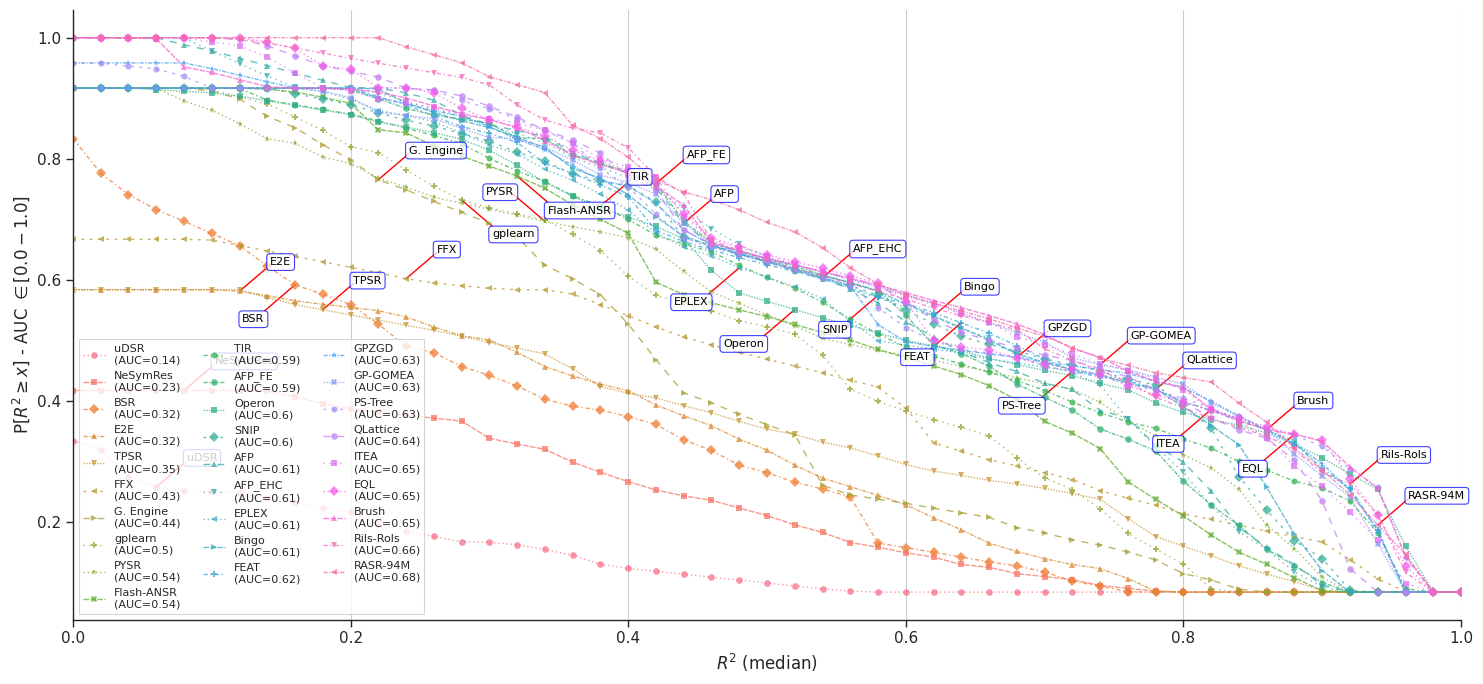

In [6]:
# TODO: I updated the AUC in the legend be consistent with the plotted curve.
# Before, in my understanding, they just took the AUC of the best seed.

def perfprof_plot(
    df,
    perf_measure,
    *,
    interval=(0.0, 1.0),
    errorbar=None,
    estimator=np.median,
    annot=True,
    ax=None,
    legend=True,
    legend_loc='lower left',
    figsize=(15, 7),
    xlabel=True,
    ylabel=True
):
    """
    Plot performance profiles across algorithms using cumulative distribution of a performance measure.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing columns: ['algorithm', 'dataset', 'random_state', perf_measure].
    perf_measure : str
        The column name of the performance metric to plot (e.g., 'r2_test').
    interval : tuple of float, optional
        Defines the interval of AUC values to include in the main plot (others are grayed out).
    errorbar : str or None, optional
        Error bar strategy passed to seaborn.lineplot (e.g., 'sd', 'se', or None).
    estimator : callable, optional
        Aggregates across random seeds at each x (and defines the AUC shown in the legend:
        AUC of that aggregated curve; default: np.median).
    annot : bool, optional
        If True, adds algorithm name annotations on the plot.
    ax : matplotlib.axes.Axes, optional
        Axis object to draw on. If None, creates a new figure.
    legend : bool, optional
        Whether to include a legend.
    legend_loc : str, optional
        Legend location (default: 'lower left').
    figsize : tuple of float, optional
        Figure size in inches, used when no axis is given.
    xlabel : bool, optional
        Whether to show the x-axis label.
    ylabel : bool, optional
        Whether to show the y-axis label.

    Returns
    -------
    matplotlib.axes.Axes
        The axis containing the performance profile plot.
    """

    dashes = [(1, 2), (4, 1), (3, 2, 1, 2), (3, 1, 1, 1), (1, 1), (2, 4), (5, 5), (1, 3)]
    dashcycler = cycle(dashes)
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*', 'X', 'h']
    markercycler = cycle(markers)

    base_fpr = np.linspace(0, 1, 51)

    suffix = "" if interval == (0.0, 1.1) else \
             f" - AUC $\\in {np.round(interval, 2).tolist()}$".replace(", ", "-").replace("(", "[")

    if ax is None:
        plt.figure(figsize=figsize)
        ax = plt.gca()

    df = df[['algorithm', 'dataset', 'random_state', perf_measure]]
    n_problems = df['dataset'].nunique()
    plot_data = []

    # Compute AUCs per algorithm across random states
    for name, view in df.groupby('algorithm'):
        view = view[view[perf_measure] >= 0].sort_values(by=perf_measure)
        frames = []

        for rs, view2 in view.groupby('random_state'):
            n_gt0 = view2.shape[0]
            perf_x, perf_y = [0], [n_gt0 / n_problems]

            # Build performance curve by counting decreasing probabilities
            for k, perf in Counter(view2[perf_measure].values).items():
                if k == 0:
                    n_gt0 -= perf
                    continue
                perf_x.append(k)
                perf_y.append(n_gt0 / n_problems)
                n_gt0 -= perf

            # Interpolate over base_fpr grid and compute AUC
            perf_y = np.interp(base_fpr, perf_x, perf_y)
            AUC_val = auc(base_fpr, perf_y)
            frames.extend({
                'perf_x': x,
                'perf_y': y,
                'random_state': rs,
                'algorithm': name,
                'AUC': AUC_val
            } for x, y in zip(base_fpr, perf_y))

        df_frames = pd.DataFrame.from_records(frames)
        if df_frames.empty:
            print(f"Warning: No valid performance data for algorithm '{name}' - skipping.")
            continue
        # AUC for legend / sorting = AUC of the curve actually drawn (same estimator as lineplot)
        agg_by_x = df_frames.groupby('perf_x')['perf_y'].agg(estimator).sort_index()
        agg_y = np.array([agg_by_x.loc[x] for x in base_fpr], dtype=float)
        AUC_plot = auc(base_fpr, agg_y)
        plot_data.append((AUC_plot, name, df_frames))

    # Sort by AUC of aggregated curve (matches drawn lines)
    plot_data.sort(key=lambda x: x[0])
    cmap = np.array(sns.color_palette("Spectral", n_colors=len(plot_data)))
    marker_dict, dashes_dict = {}, {}
    algs_in = pd.DataFrame()
    c_idxs = []

    # Plot algorithms inside/outside the AUC interval
    for i, (AUC_val, name, df_frames) in enumerate(plot_data):
        pretty_name = f'{name}\n(AUC={np.round(AUC_val, 2)})'
        df_frames['algorithm'] = pretty_name

        if interval[0] <= np.round(AUC_val, 2) < interval[1]:
            marker_dict[pretty_name] = next(markercycler)
            dashes_dict[pretty_name] = next(dashcycler)
            algs_in = pd.concat([algs_in, df_frames])
            c_idxs.append(i)
        elif np.isfinite(AUC_val):
            sns.lineplot(
                data=df_frames, x='perf_x', y='perf_y', linewidth=1, ls=":", ax=ax,
                alpha=0.2, color='gray', errorbar=None, label=None, estimator=estimator
            )

    # Plot colored curves for algorithms in interval
    if not algs_in.empty:
        ax = sns.lineplot(
            data=algs_in, x='perf_x', y='perf_y', linewidth=1, ax=ax,
            color=cmap[c_idxs], errorbar=errorbar, estimator=estimator,
            hue='algorithm', style='algorithm', alpha=0.75,
            markeredgewidth=0, markers=marker_dict, dashes=dashes_dict
        )

        if annot:
            # Compute representative positions for text annotations
            grouped_lines = algs_in.groupby(['algorithm', 'perf_x']).agg(estimator)\
                                   .reset_index().sort_values('AUC')

            closest_fpr_point = lambda p: min(base_fpr, key=lambda x: abs(x - p))
            x = [closest_fpr_point(xpos) for xpos in np.linspace(0.05, 0.95, len(grouped_lines['algorithm'].unique()))]
            y = [grouped_lines[grouped_lines['perf_x'] == xpos]['perf_y'].max() for xpos in x]
            y_line = [
                grouped_lines[
                    (grouped_lines['perf_x'] == closest_fpr_point(xpos)) &
                    (grouped_lines['algorithm'] == alg)
                ]['perf_y'].max()
                for xpos, alg in zip(x, grouped_lines['algorithm'].unique())
            ]

            names = grouped_lines['algorithm'].str.replace(r"\s*\(AUC=.*\)", "", regex=True).unique()
            ta.allocate(
                ax, x, y_line, names,
                min_distance=0.02, avoid_label_lines_overlap=True, avoid_crossing_label_lines=True,
                x_scatter=x, y_scatter=y, textsize=FONT_SIZE,
                fontweight=['bold' if is_rasr(n) else 'normal' for n in names],
                **{"bbox": dict(facecolor='w', edgecolor='b', boxstyle='round', alpha=0.75)}
            )

    # Axis formatting
    ax.set_xlim((0, 1.0))
    label = perf_measure.replace('_', ' ').replace(' test', '').replace('r2', 'R^2').title()

    if xlabel:
        if df['random_state'].nunique() == 1:
            ax.set_xlabel(f"${label}$")
        else:
            ax.set_xlabel(f"${label}$ ({estimator.__name__})")
    else:
        ax.set_xlabel("")

    if ylabel:
        ax.set_ylabel(f"P[${label} \\geq x$]{suffix}")
    else:
        ax.set_ylabel("")

    if legend:
        leg = ax.legend(
            loc=legend_loc, ncol=3, fancybox=False, shadow=False, prop={'size': FONT_SIZE}
        )
        for legobj in leg.legend_handles:
            legobj.set_linewidth(1.0)
        for text in leg.get_texts():
            if is_rasr(text.get_text()):
                text.set_fontweight('bold')
    else:
        ax.get_legend().remove()

    ax.grid(axis='x')
    sns.despine()

    return ax

# Examples on how to generate different perfplots ------------------------------
# perfprof_plot(df_plot, "r2_test", errorbar=None, estimator=np.min)
# perfprof_plot(df_plot, "r2_test", errorbar=None, estimator=np.max)

# Keep only rasr_94m_pt_final_cw5e-2 among the rasr_* runs, renamed to RASR-94M-L
r2_full_algs = [a for a in df_plot['algorithm'].unique() if ('rasr_94m' == a.lower() or 'rasr' not in a.lower())]
df_plot_r2_full = df_plot[df_plot['algorithm'].isin(r2_full_algs)].copy()
df_plot_r2_full['algorithm'] = df_plot_r2_full['algorithm'].replace({'rasr_94m': 'RASR-94M-L'})

# Saved at the size it is printed in the paper: rotated by 90 degrees on its own page, so
# the figure is landscape and its width is the page height.
perfprof_plot(
    df_plot_r2_full, "r2_test", errorbar=None, estimator=np.median,
    figsize=(7.9, 5.1)
)
save(name='r2_perf_full', figdir=figdir)

Saving ../figs/black-box/r2_perf_intervals.pdf


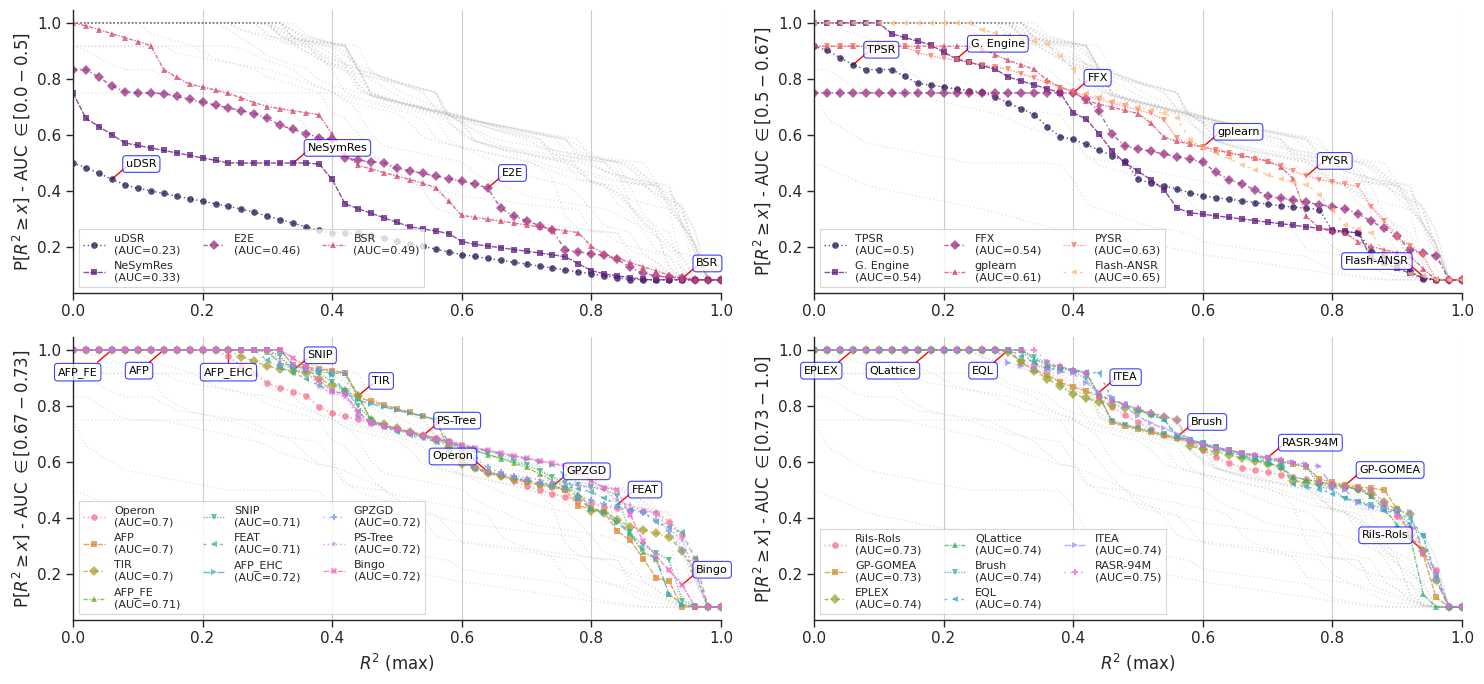

In [7]:
# Four panels stacked vertically, saved at the full width and height of a portrait page.
fig, axs = plt.subplots(4, 1, figsize=(5.5, 7.8))

# Selecting based on overall performance
intervals = [(0, 0.5), (0.5, 0.67), (0.67, 0.73), (0.73, 1.0)]
for i, (ax, interval) in enumerate(zip(axs, intervals)):
    perfprof_plot(
        df_plot_r2_full, "r2_test", interval=interval, errorbar=None, estimator=np.max, ax=ax,
        legend=True,
        xlabel=i == len(intervals) - 1
    )

save(name=f'r2_perf_intervals'.replace(", ", "-"), figdir=figdir)

# Summarizing performance profiles as tables with AUC

Saving ../figs/black-box/r2_AUC_tuning.pdf


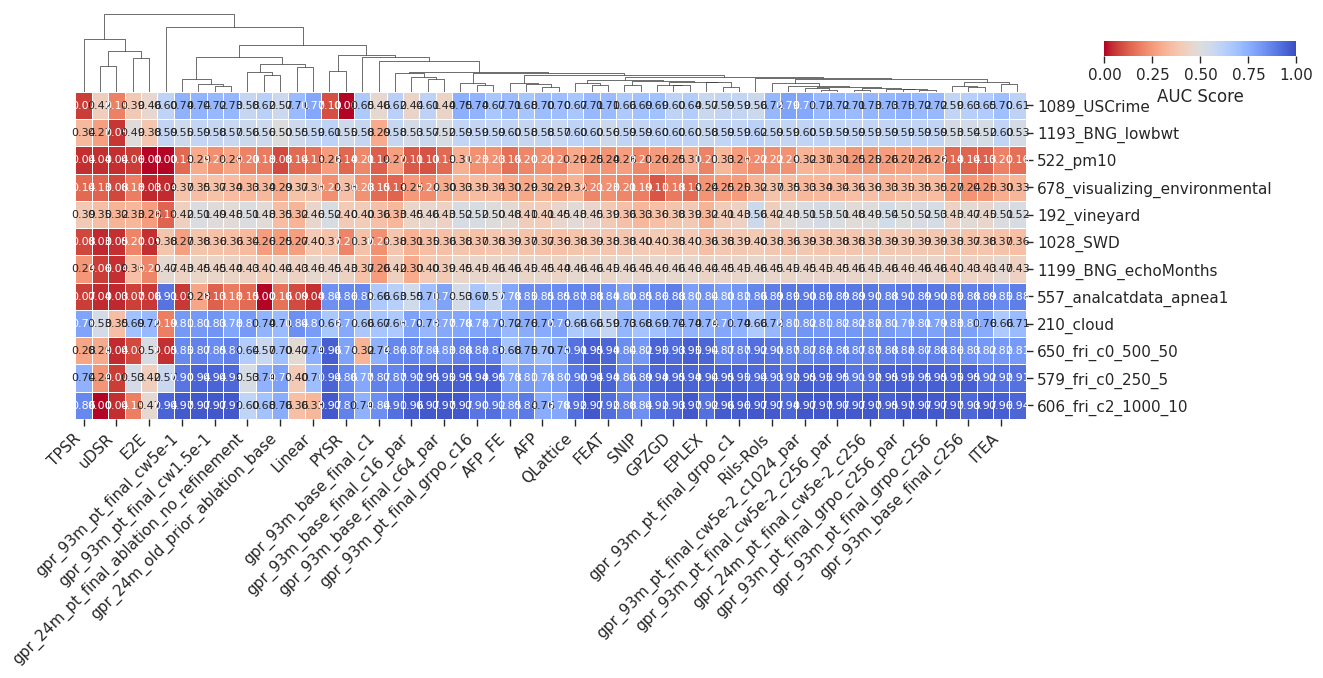

In [6]:
def perf_table(df, perf_measure, interval=(0.0, 1.0), errorbar=None):
    """
    Compute a performance summary table (AUC and model size) for each algorithm-dataset pair.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing ['algorithm', 'dataset', 'random_state', perf_measure, 'model_size'].
    perf_measure : str
        Name of the performance metric column (e.g., 'r2_test').
    interval : tuple of float, optional
        Unused here but kept for consistency with related plotting functions.
    errorbar : str or None, optional
        Placeholder parameter for compatibility (not used).

    Returns
    -------
    pandas.DataFrame
        Table containing per-algorithm, per-dataset statistics:
        ['algorithm', 'dataset', 'AUC', 'mean_model_size', 'valid'].
    """
    base_fpr = np.linspace(0, 1, 51)
    df = df[['algorithm', 'dataset', 'random_state', perf_measure, 'model_size']]
    n_problems = df['random_state'].nunique()
    data = []

    # Compute AUC and mean model size for each algorithm-dataset pair
    for (alg, ds), view in df.groupby(['algorithm', 'dataset']):
        view = view[view[perf_measure] >= 0].sort_values(by=perf_measure)
        n_gt0 = view.shape[0]

        if n_gt0==0: # ignoring groups with no results
            continue

        perf_x, perf_y = [0], [n_gt0 / n_problems]

        # Build performance curve
        for k, perf in Counter(view[perf_measure].values).items():
            if k == 0:
                n_gt0 -= perf
                continue
            perf_x.append(k)
            perf_y.append(n_gt0 / n_problems)
            n_gt0 -= perf

        # Interpolate and compute AUC
        perf_y = np.interp(base_fpr, perf_x, perf_y)
        AUC_val = auc(base_fpr, perf_y)
        mean_size = np.mean(view['model_size'].values)
        counts = (view['model_size'] > 0).sum()
        data.append((alg, ds, AUC_val, mean_size, counts))

    perf_table_df = pd.DataFrame(
        data=data,
        columns=['algorithm', 'dataset', 'AUC', 'mean_model_size', 'valid']
    )
    return perf_table_df


# === Generate and visualize the performance table ===
perf_table_df = perf_table(df_plot, "r2_test", errorbar=None).drop(columns=['mean_model_size'])
perf_table_pivot = perf_table_df.pivot(columns='algorithm', index='dataset', values='AUC').fillna(0.0)

# display(perf_table_pivot.style.background_gradient(axis=None, cmap='coolwarm_r'))

g_cluster = sns.clustermap(
    perf_table_pivot,
    annot=True,
    fmt='.2f',
    cmap='coolwarm_r',
    center=0.5,
    vmin=0,
    vmax=1,
    annot_kws={'size': 8},
    linewidths=0.5,
    square=False,
    cbar_pos=(.86, .92, .128, .019),
    # cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'AUC Score', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_cluster.ax_heatmap.set_ylabel("")
g_cluster.ax_heatmap.set_xlabel("")
g_cluster.ax_row_dendrogram.set_visible(False) 

plt.setp(g_cluster.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
save(name='r2_AUC_tuning', figdir=figdir, tight_layout=False)

# Sumarizing model sizes by keeping clusters from the previous heatmap

Filling missing values or bad sizes with median size 28.0


Saving ../figs/black-box/model_sizes.pdf


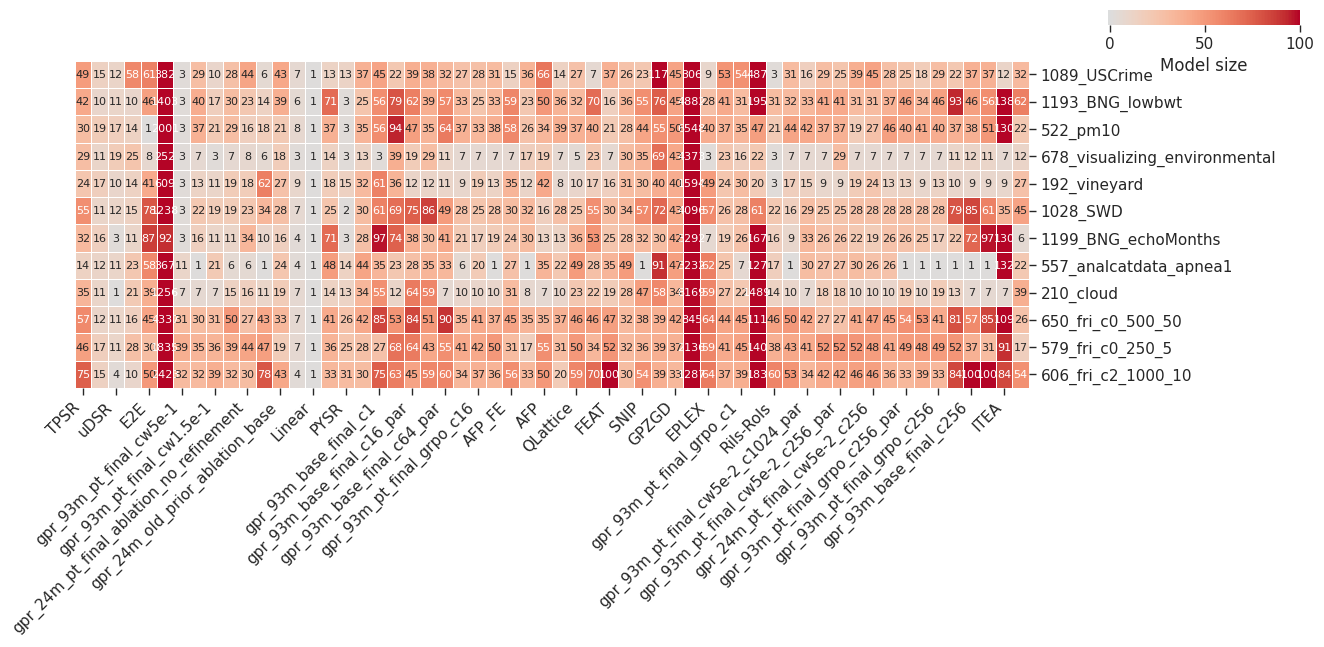

In [7]:
# === Size of the best expressions ===
df_plot_heatmap = df_plot.copy().dropna(subset=['r2_zero_test', 'model_size'])

# Replace or remove invalid sizes
med_size = np.nanmedian(df_plot_heatmap.loc[df_plot_heatmap['model_size'] > 0, 'model_size'])
print("Filling missing values or bad sizes with median size", med_size)
mask = df_plot_heatmap['model_size'] <= 0
df_plot_heatmap.loc[mask, 'model_size'] = med_size

# Select best performing r2 per (algorithm, dataset)
df_plot_heatmap = (
    df_plot_heatmap
    .sort_values(['algorithm', 'dataset', 'r2_zero_test', 'model_size'], ascending=[True, True, False, True])
    .drop_duplicates(subset=['algorithm', 'dataset'], keep='first')
    [['algorithm', 'dataset', 'model_size']]
)

# Pivot table
df_plot_heatmap = df_plot_heatmap.pivot(index='dataset', columns='algorithm', values='model_size')

# Fill missing algorithm results
df_plot_heatmap = df_plot_heatmap.fillna(df_plot_heatmap.mean())

# Reorder to match dendrogram
df_plot_heatmap = df_plot_heatmap.iloc[g_cluster.dendrogram_row.reordered_ind, :]
df_plot_heatmap = df_plot_heatmap.iloc[:, g_cluster.dendrogram_col.reordered_ind]

# Plot
g = sns.clustermap(
    df_plot_heatmap,
    annot=True,
    fmt='.0f',
    cmap='coolwarm',
    vmin=-1,
    center=0,
    vmax=100,
    annot_kws={'size': 8},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.86, .92, .128, .019),
    cbar_kws={'label': 'Model size', "orientation": "horizontal"},
    figsize=(15, 8)
)

# Final touches
g.ax_heatmap.set_ylabel("")
g.ax_heatmap.set_xlabel("")
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')

save(name='model_sizes', figdir=figdir, tight_layout=False)

# Plotting AUC and size together

Using cell size to represent average model sizes

Filling missing or invalid sizes with median size: 28.0


Saving ../figs/black-box/r2_AUC_tuning_with_sizes.pdf


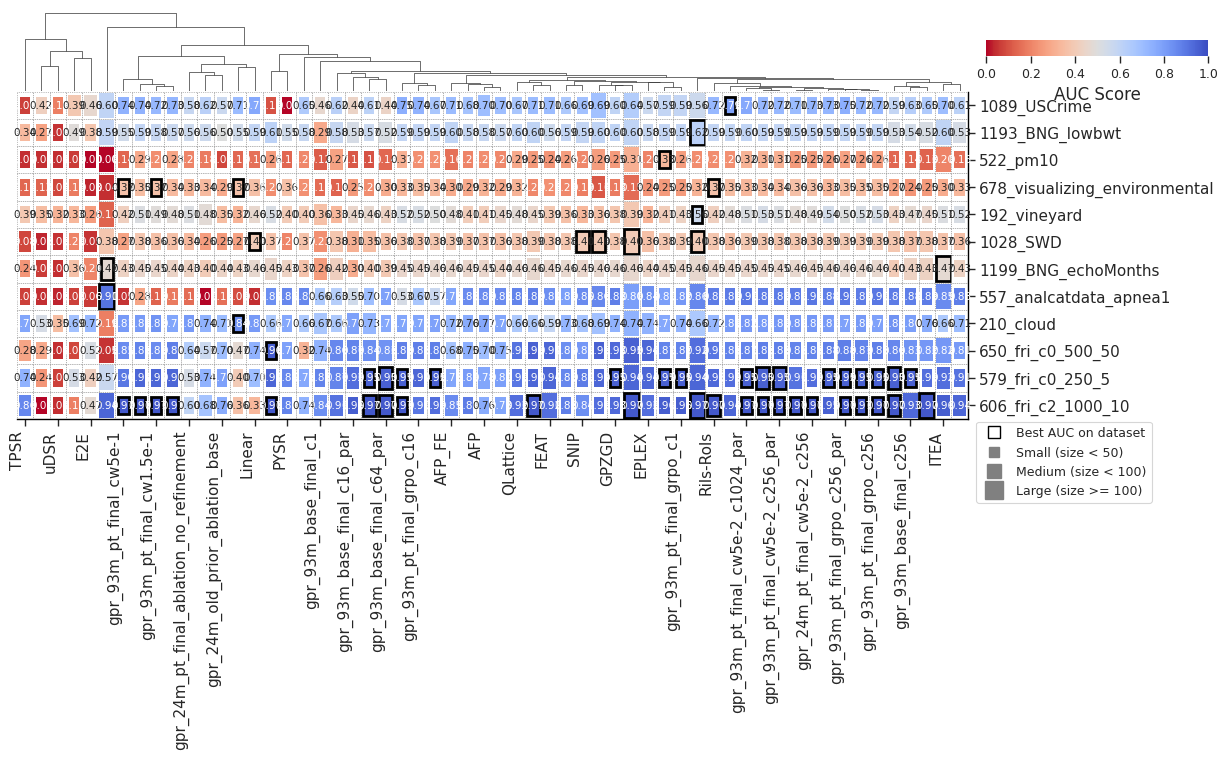

In [8]:
# === Combining both AUC and size ===
df_plot_aux = df_plot.copy()

# Replace invalid model sizes with median
valid_sizes = df_plot_aux.loc[df_plot_aux['model_size'] > 0, 'model_size']
med_size = np.nanmedian(valid_sizes) if not valid_sizes.empty else 50
print("Filling missing or invalid sizes with median size:", med_size)

mask = df_plot_aux['model_size'] <= 0
df_plot_aux.loc[mask, 'model_size'] = med_size

# Keep only valid
df_plot_aux = df_plot_aux[df_plot_aux['model_size'] > 0]

# Compute AUC performance table
perf_table_df = perf_table(df_plot_aux, "r2_test", errorbar=None)

# Number of valid runs (for transparency)
counts_table_pivot = perf_table_df.pivot(columns='algorithm', index='dataset', values='valid').fillna(0.0)
counts_table_pivot = counts_table_pivot.iloc[g_cluster.dendrogram_row.reordered_ind]

# Pivot AUC results
perf_table_pivot = perf_table_df.pivot(columns='algorithm', index='dataset', values='AUC').fillna(0.0)
perf_table_pivot = perf_table_pivot.iloc[g_cluster.dendrogram_row.reordered_ind, g_cluster.dendrogram_col.reordered_ind]

# Reuse same column order as previous clustering (important)
g_cluster2 = sns.clustermap(
    perf_table_pivot,
    annot=True,
    fmt='.2f',
    cmap='coolwarm_r',
    center=0.5,
    vmin=0,
    vmax=1,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'AUC Score', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_cluster2.ax_cbar.tick_params(labelsize=9)
g_cluster2.ax_heatmap.set_ylabel("")
g_cluster2.ax_heatmap.set_xlabel("")
g_cluster2.ax_row_dendrogram.set_visible(False)
plt.setp(g_cluster2.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

# Identify best models
best_idxs = []
flat_index = 0
for i in range(perf_table_pivot.shape[0]):
    values = perf_table_pivot.iloc[i].round(2).values
    not_nan_values = values[~np.isnan(values)]
    if len(not_nan_values) == 0:
        continue
    best_idxs += [flat_index + j for j, val in enumerate(not_nan_values) if val == np.nanmax(not_nan_values)]
    flat_index += len(not_nan_values)

# Overlay model size boxes
texts_auc = g_cluster2.ax_heatmap.texts
texts_size = g.ax_heatmap.texts

for i, (t_auc, t_size) in enumerate(zip(texts_auc, texts_size)):
    if t_auc.get_text() == '' or t_size.get_text() == '':
        # No data: draw empty gray box
        g_cluster2.ax_heatmap.add_patch(Rectangle(
            [p - 0.5 for p in t_size.get_position()], 1, 1, fc='white', ec='gray', lw=0.5, ls=':'
        ))
        continue

    model_size = int(t_size.get_text())
    # Discrete mapping
    if model_size >= 100:
        rate = -0.05
    elif model_size > 50:
        rate = 0.4
    else:
        rate = 0.9
    totsize = 0.9 - rate * 0.3

    # Reconstruct color from colormap instead of facecolor index
    cmap = plt.get_cmap('coolwarm_r')
    auc_val = float(t_auc.get_text())
    c = cmap((auc_val - 0) / (1 - 0))

    # Border box (background)
    g_cluster2.ax_heatmap.add_patch(Rectangle(
        [p - 0.5 for p in t_size.get_position()], 1, 1, fc='white', ec='gray', lw=0.5, ls=':'
    ))

    # Main proportional box
    if i in best_idxs:
        g_cluster2.ax_heatmap.add_patch(Rectangle(
            [p - (totsize / 2) for p in t_size.get_position()],
            totsize, totsize, fc=c, ec='black', lw=2
        ))
    else:
        g_cluster2.ax_heatmap.add_patch(Rectangle(
            [p - (totsize / 2) for p in t_size.get_position()],
            totsize, totsize, fc=c, ec='none', lw=0
        ))

# Frame borders
for key, spine in g_cluster2.ax_heatmap.spines.items():
    if key not in ('left', 'top'):
        spine.set_visible(True)
        spine.set_edgecolor('black')

# Legend
patch_best = g_cluster2.ax_heatmap.plot([],[], marker='s', ms=8, lw=2, markeredgecolor='k', color='white', label='Best AUC on dataset')
patch_small = g_cluster2.ax_heatmap.plot([],[], marker='s', ms=7, ls="", color='gray', label='Small (size < 50)')
patch_medium = g_cluster2.ax_heatmap.plot([],[], marker='s', ms=10, ls="", color='gray', label='Medium (size < 100)')
patch_large = g_cluster2.ax_heatmap.plot([],[], marker='s', ms=13, ls="", color='gray', label='Large (size >= 100)')
g_cluster2.ax_heatmap.legend(handles=patch_best+patch_small+patch_medium+patch_large, bbox_to_anchor=(1.2, 0.01), fontsize=9)

save(name='r2_AUC_tuning_with_sizes', figdir=figdir, tight_layout=False)

# Median R² test per dataset

Saving ../figs/black-box/median_r2_heatmap.pdf


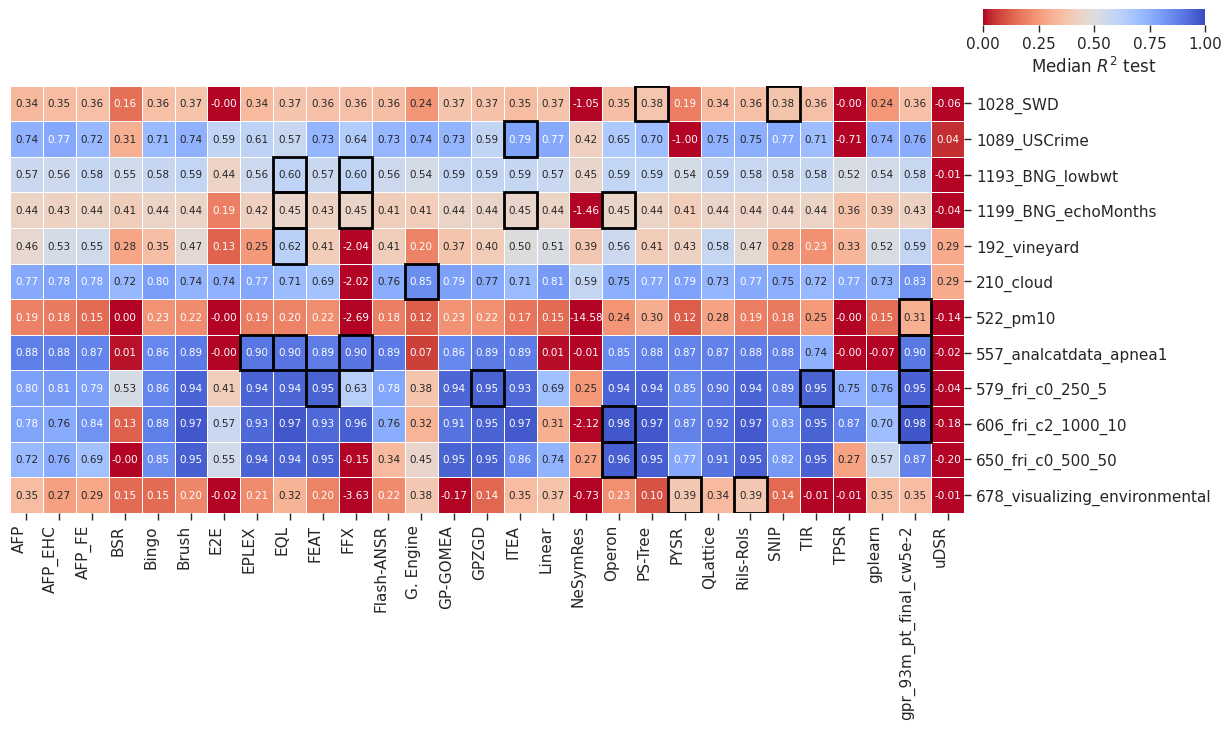

In [9]:
# Compute median r2_test per (algorithm, dataset) across random seeds
constants_algs = [a for a in df_plot['algorithm'].unique() if ('rasr_94m' == a.lower() or 'rasr' not in a.lower())]


median_r2_pivot = (
    df_plot[df_plot['algorithm'].isin(constants_algs)]
    .groupby(['algorithm', 'dataset'])['r2_test']
    .median()
    .reset_index()
    .pivot(index='dataset', columns='algorithm', values='r2_test')
    .fillna(-1)
)

# Reuse row/column ordering from AUC clustering
# median_r2_pivot = median_r2_pivot.iloc[
#     g_cluster.dendrogram_row.reordered_ind,
#     g_cluster.dendrogram_col.reordered_ind
# ]

g_median = sns.clustermap(
    median_r2_pivot,
    annot=True,
    fmt='.2f',
    cmap='coolwarm_r',
    center=0.5,
    vmin=0,
    vmax=1,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'Median $R^2$ test', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_median.ax_heatmap.set_ylabel("")
g_median.ax_heatmap.set_xlabel("")
g_median.ax_row_dendrogram.set_visible(False)
g_median.ax_col_dendrogram.set_visible(False)
plt.setp(g_median.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

# Mark best algorithm per dataset with a thick black border
n_cols = median_r2_pivot.shape[1]
for i in range(median_r2_pivot.shape[0]):
    row_vals = median_r2_pivot.iloc[i].values
    best_val = np.nanmax(row_vals)
    for j, val in enumerate(row_vals):
        if round(val, 2) == round(best_val, 2):
            tx, ty = g_median.ax_heatmap.texts[i * n_cols + j].get_position()
            g_median.ax_heatmap.add_patch(Rectangle(
                (tx - 0.5, ty - 0.5), 1, 1, fill=False, ec='black', lw=2
            ))

save(name='median_r2_heatmap', figdir=figdir, tight_layout=False)

Saving ../figs/black-box/median_r2_constants_heatmap.pdf


Mean median-R² test per method (all 12 datasets vs 8 targeted-size datasets):
                         mean_r2_all_datasets  mean_r2_targeted_size
algorithm                                                           
rasr_94m_pt_final_cw5e-2                0.6584                 0.6571
EQL                                    0.6339                 0.6293
QLattice                               0.6374                 0.6207
Rils-Rols                              0.6396                 0.6202
Operon                                 0.6294                 0.6123
ITEA                                   0.6280                 0.6070
Brush                                  0.6274                 0.6000
PS-Tree                                0.6198                 0.5944
GPZGD                                  0.6045                 0.5852
FEAT                                   0.6093                 0.5794
AFP_FE                                 0.5876                 0.5775
AFP                     

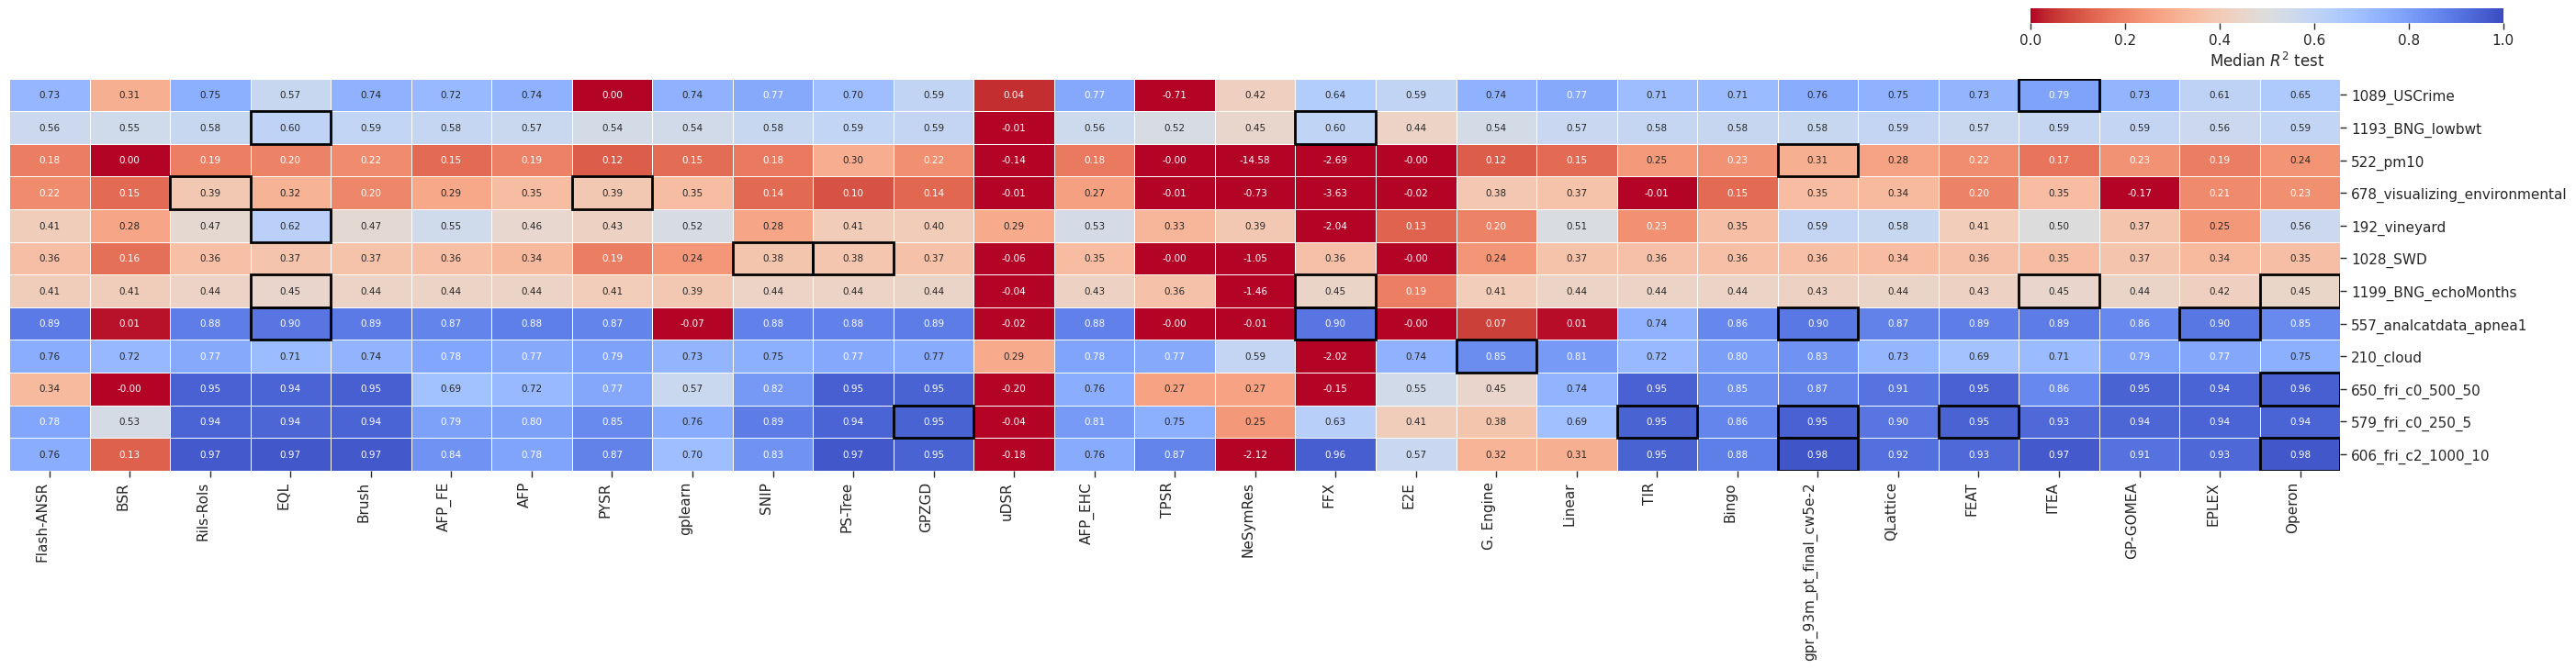

In [10]:
# Compute median r2_test per (algorithm, dataset) — only algorithms with "constants" in their name
constants_algs = [a for a in df_plot['algorithm'].unique() if ('rasr_94m' == a.lower() or 'rasr' not in a.lower())]

median_r2_constants_pivot = (
    df_plot[df_plot['algorithm'].isin(constants_algs)]
    .groupby(['algorithm', 'dataset'])['r2_test']
    .median()
    .reset_index()
    .pivot(index='dataset', columns='algorithm', values='r2_test')
    .fillna(0.0)
)

# Reuse row ordering from AUC clustering; filter column ordering to constants algorithms
row_order = [i for i in g_cluster.dendrogram_row.reordered_ind
             if median_r2_constants_pivot.index[i] in median_r2_constants_pivot.index]
col_order = [i for i in g_cluster.dendrogram_col.reordered_ind
             if g_cluster.data2d.columns[i] in median_r2_constants_pivot.columns]

median_r2_constants_pivot = median_r2_constants_pivot.loc[
    [median_r2_constants_pivot.index[i] for i in row_order],
    [g_cluster.data2d.columns[i] for i in col_order]
]

n_cols = median_r2_constants_pivot.shape[1]
fig_width = max(4, n_cols * 1.2)

g_median_constants = sns.clustermap(
    median_r2_constants_pivot,
    annot=True,
    fmt='.2f',
    cmap='coolwarm_r',
    center=0.5,
    vmin=0,
    vmax=1,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'Median $R^2$ test', "orientation": "horizontal"},
    figsize=(fig_width, 8)
)

g_median_constants.ax_heatmap.set_ylabel("")
g_median_constants.ax_heatmap.set_xlabel("")
g_median_constants.ax_row_dendrogram.set_visible(False)
g_median_constants.ax_col_dendrogram.set_visible(False)
plt.setp(g_median_constants.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

# Mark best algorithm per dataset with a thick black border
n_cols_heat = median_r2_constants_pivot.shape[1]
for i in range(median_r2_constants_pivot.shape[0]):
    row_vals = median_r2_constants_pivot.iloc[i].values
    best_val = np.nanmax(row_vals)
    for j, val in enumerate(row_vals):
        if round(val, 2) == round(best_val, 2):
            tx, ty = g_median_constants.ax_heatmap.texts[i * n_cols_heat + j].get_position()
            g_median_constants.ax_heatmap.add_patch(Rectangle(
                (tx - 0.5, ty - 0.5), 1, 1, fill=False, ec='black', lw=2
            ))

save(name='median_r2_constants_heatmap', figdir=figdir, tight_layout=False)

# Mean median-R² test per method, over all datasets and over the targeted-size datasets
excluded_datasets = ['1089_USCrime', '1193_BNG_lowbwt', '1199_BNG_echoMonths', '650_fri_c0_500_50']

mean_r2_all = median_r2_constants_pivot.mean(axis=0)
mean_r2_targeted = (
    median_r2_constants_pivot.drop(index=excluded_datasets, errors='ignore').mean(axis=0)
)

mean_r2_summary = pd.DataFrame({
    'mean_r2_all_datasets': mean_r2_all,
    'mean_r2_targeted_size': mean_r2_targeted,
}).sort_values('mean_r2_targeted_size', ascending=False)

print(f"Mean median-R² test per method (all {median_r2_constants_pivot.shape[0]} datasets vs "
      f"{median_r2_constants_pivot.drop(index=excluded_datasets, errors='ignore').shape[0]} targeted-size datasets):")
print(mean_r2_summary.to_string(float_format=lambda x: f'{x:.4f}'))

Saving ../figs/black-box/median_model_size_heatmap.pdf


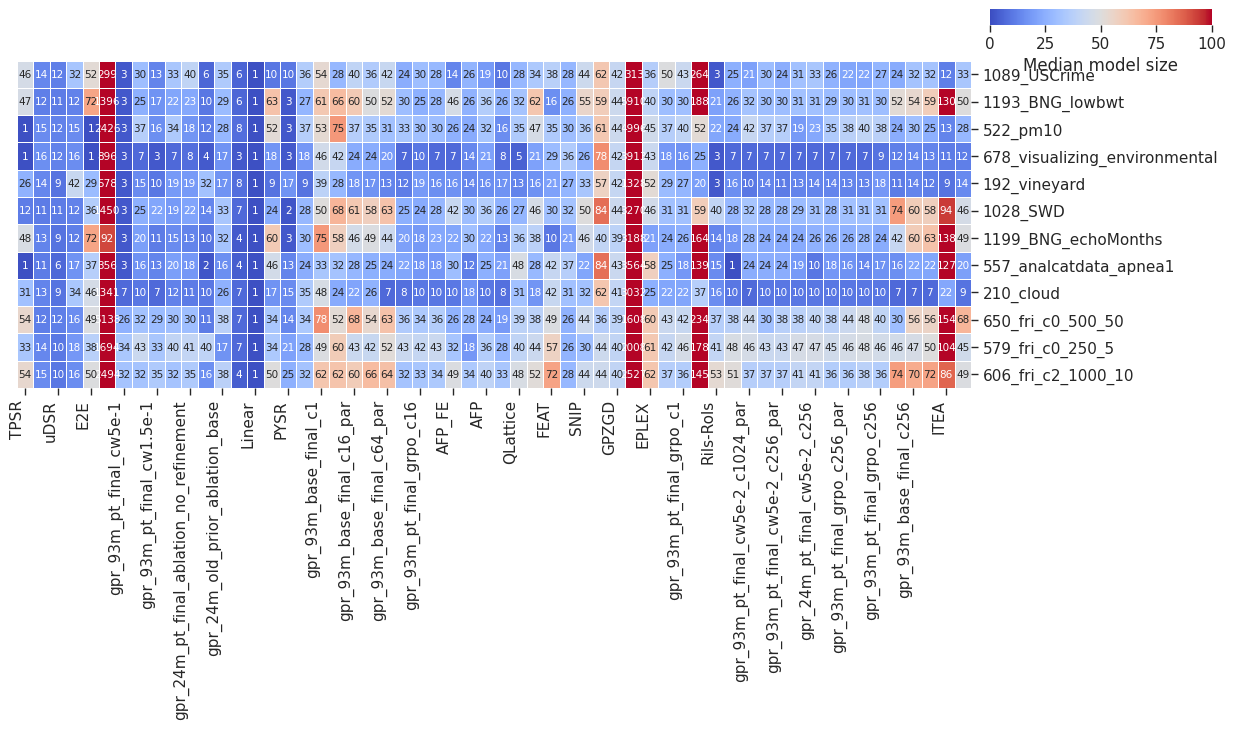

In [11]:
# Compute median model_size per (algorithm, dataset) across seeds
median_size_pivot = (
    df_plot
    .groupby(['algorithm', 'dataset'])['model_size']
    .median()
    .reset_index()
    .pivot(index='dataset', columns='algorithm', values='model_size')
    .fillna(df_plot.groupby('algorithm')['model_size'].median())  # fill missing with per-algorithm median
)

# Reuse row/column ordering from AUC clustering
median_size_pivot = median_size_pivot.iloc[
    g_cluster.dendrogram_row.reordered_ind,
    g_cluster.dendrogram_col.reordered_ind
]

g_size = sns.clustermap(
    median_size_pivot,
    annot=True,
    fmt='.0f',
    cmap='coolwarm',
    center=50,
    vmin=0,
    vmax=100,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'Median model size', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_size.ax_heatmap.set_ylabel("")
g_size.ax_heatmap.set_xlabel("")
g_size.ax_row_dendrogram.set_visible(False)
g_size.ax_col_dendrogram.set_visible(False)
plt.setp(g_size.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

save(name='median_model_size_heatmap', figdir=figdir, tight_layout=False)

In [12]:
# Compute median model_size per (algorithm, dataset) — only algorithms with "constants" in their name
constants_algs = [a for a in df_plot['algorithm'].unique() if 'constants' in a.lower()]

median_size_constants_pivot = (
    df_plot[df_plot['algorithm'].isin(constants_algs)]
    .groupby(['algorithm', 'dataset'])['model_size']
    .median()
    .reset_index()
    .pivot(index='dataset', columns='algorithm', values='model_size')
    .fillna(df_plot[df_plot['algorithm'].isin(constants_algs)].groupby('algorithm')['model_size'].median())
)

# Reuse row ordering from AUC clustering; filter column ordering to constants algorithms
row_order = [i for i in g_cluster.dendrogram_row.reordered_ind
             if median_size_constants_pivot.index[i] in median_size_constants_pivot.index]
col_order = [i for i in g_cluster.dendrogram_col.reordered_ind
             if g_cluster.data2d.columns[i] in median_size_constants_pivot.columns]

median_size_constants_pivot = median_size_constants_pivot.loc[
    [median_size_constants_pivot.index[i] for i in row_order],
    [g_cluster.data2d.columns[i] for i in col_order]
]

g_size_constants = sns.clustermap(
    median_size_constants_pivot,
    annot=True,
    fmt='.0f',
    cmap='coolwarm',
    center=50,
    vmin=0,
    vmax=100,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'Median model size (constants methods)', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_size_constants.ax_heatmap.set_ylabel("")
g_size_constants.ax_heatmap.set_xlabel("")
g_size_constants.ax_row_dendrogram.set_visible(False)
g_size_constants.ax_col_dendrogram.set_visible(False)
plt.setp(g_size_constants.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

save(name='median_model_size_constants_heatmap', figdir=figdir, tight_layout=False)

IndexError: index out of bounds

# Std of R² test per dataset

Saving ../figs/black-box/std_r2_heatmap.pdf


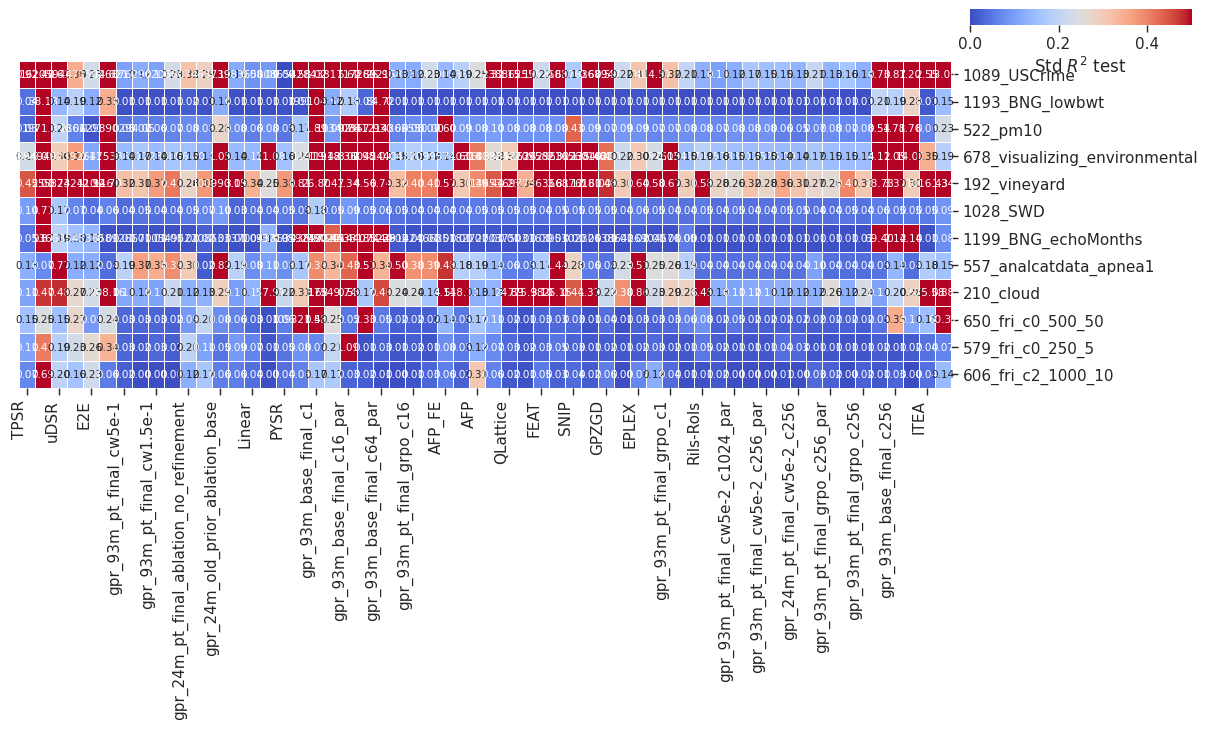

In [13]:
# Compute std of r2_test per (algorithm, dataset) across random seeds
std_r2_pivot = (
    df_plot
    .groupby(['algorithm', 'dataset'])['r2_test']
    .std()
    .reset_index()
    .pivot(index='dataset', columns='algorithm', values='r2_test')
    .fillna(0.0)
)

# Reuse row/column ordering from AUC clustering
std_r2_pivot = std_r2_pivot.iloc[
    g_cluster.dendrogram_row.reordered_ind,
    g_cluster.dendrogram_col.reordered_ind
]

g_std = sns.clustermap(
    std_r2_pivot,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0.25,
    vmin=0,
    vmax=0.5,
    annot_kws={'size': 7.5},
    linewidths=0.5,
    square=False,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'Std $R^2$ test', "orientation": "horizontal"},
    figsize=(15, 8)
)

g_std.ax_heatmap.set_ylabel("")
g_std.ax_heatmap.set_xlabel("")
g_std.ax_row_dendrogram.set_visible(False)
g_std.ax_col_dendrogram.set_visible(False)
plt.setp(g_std.ax_heatmap.get_xticklabels(), rotation=90, ha='right')

save(name='std_r2_heatmap', figdir=figdir, tight_layout=False)

# Performance plots for each dataset

Saving ../figs/black-box/r2_perf_intervals_522_pm10.pdf


Saving ../figs/black-box/r2_perf_intervals_557_analcatdata_apnea1.pdf


/tmp/ipykernel_1024475/1850906638.py:184: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = ax.legend(loc=legend_loc, ncol=3, fancybox=False, shadow=False, prop={'size': 8})


Saving ../figs/black-box/r2_perf_intervals_606_fri_c2_1000_10.pdf


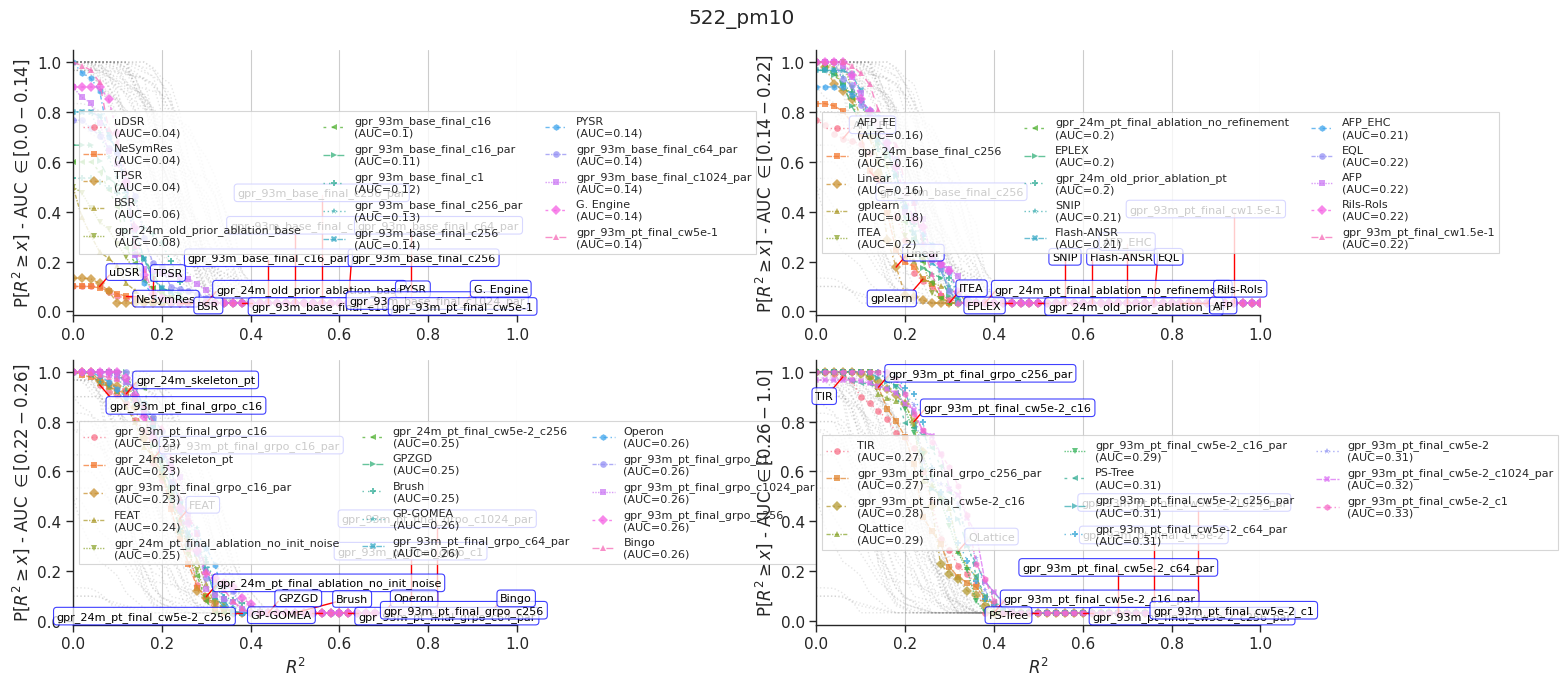

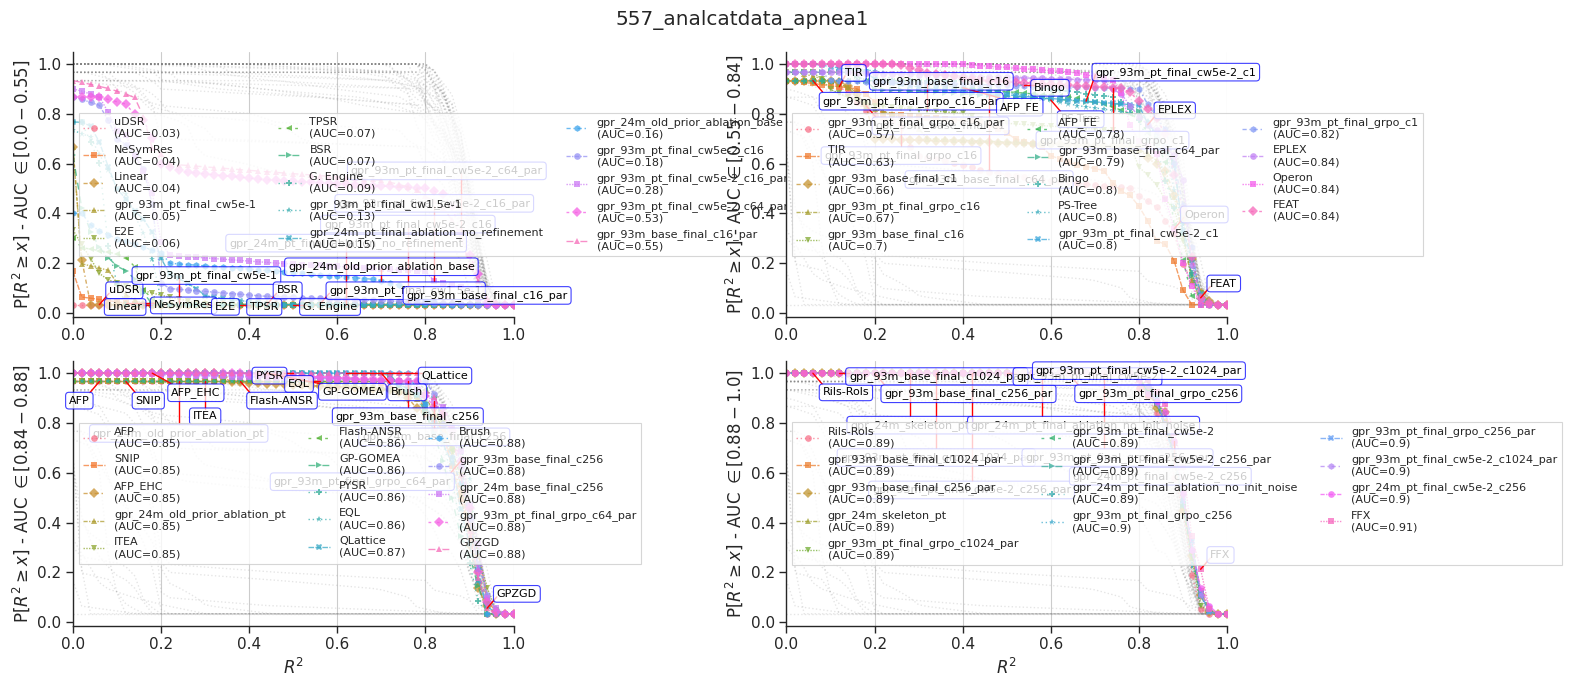

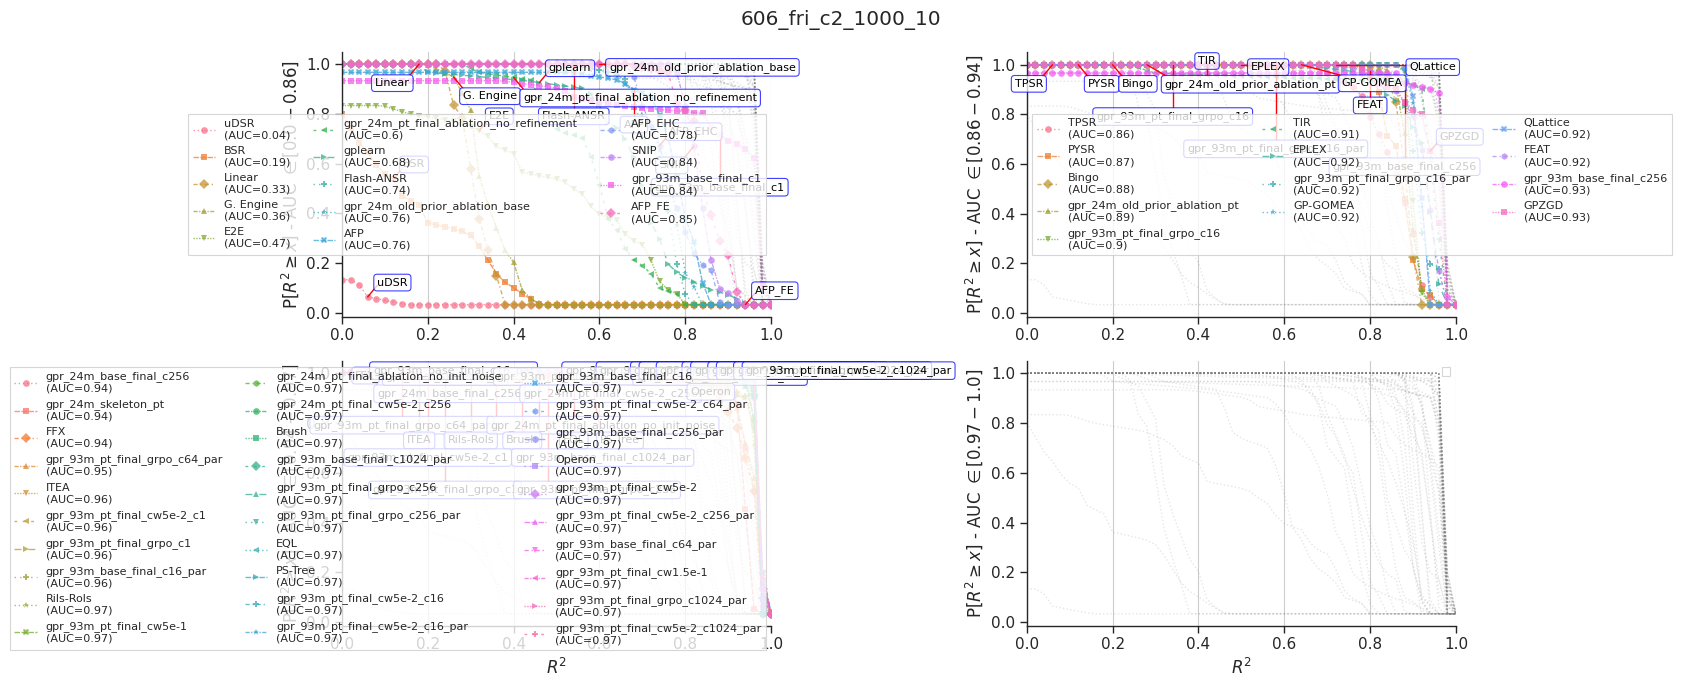

In [14]:
# Compute AUC per algorithm–dataset and reshape
perf_table_df = perf_table(df_plot, "r2_test", errorbar=None).drop(columns=['mean_model_size'])
perf_table_pivot = perf_table_df.pivot(columns='dataset', index='algorithm', values='AUC')

for ds in [
    # '1028_SWD', 
    # '1089_USCrime', 
    # '1193_BNG_lowbwt', 
    # '1199_BNG_echoMonths', 
    # '192_vineyard', 
    # '210_cloud', 
    '522_pm10', 
    '557_analcatdata_apnea1', 
    # '579_fri_c0_250_5', 
    '606_fri_c2_1000_10',
    # '650_fri_c0_500_50',
    # '678_visualizing_environmental'
]:
    data = df_plot[df_plot['dataset'] == ds].copy()

    # Fake dataset labels to simulate different trials for profiling visualization
    data['dataset'] = data['random_state'].astype(str)
    data['random_state'] = 123

    if data.empty:
        continue

    fig, axs = plt.subplots(2, 2, figsize=(15, 7))

    # Determine quartile intervals of AUC for grouping algorithms by performance
    try:
        data_quartiles = perf_table_pivot[ds].dropna().values
        q1, q2, q3 = np.quantile(data_quartiles, [0.25, 0.5, 0.75], method='midpoint')
        intervals = [(0, q1), (q1, q2), (q2, q3), (q3, 1.0)]
    except Exception as e:
        warnings.warn(f"Failed to compute quartiles for dataset {ds}: {e}")
        traceback.print_exc()
        continue

    # Plot performance profiles for each quartile range
    for i, (ax, interval) in enumerate(zip(fig.axes, intervals)):
        perfprof_plot(
            data,
            "r2_test",
            interval=interval,
            errorbar='ci',
            estimator=np.mean,
            ax=ax,
            legend=True,
            legend_loc='best',
            xlabel=i > 1  # Only label x-axis on bottom row
        )

    fig.subplots_adjust(top=0.93)
    fig.suptitle(ds, y=0.98)
    save(name=f'r2_perf_intervals_{ds}', figdir=figdir)


# Table with training times

Saving ../figs/black-box/training_time.pdf


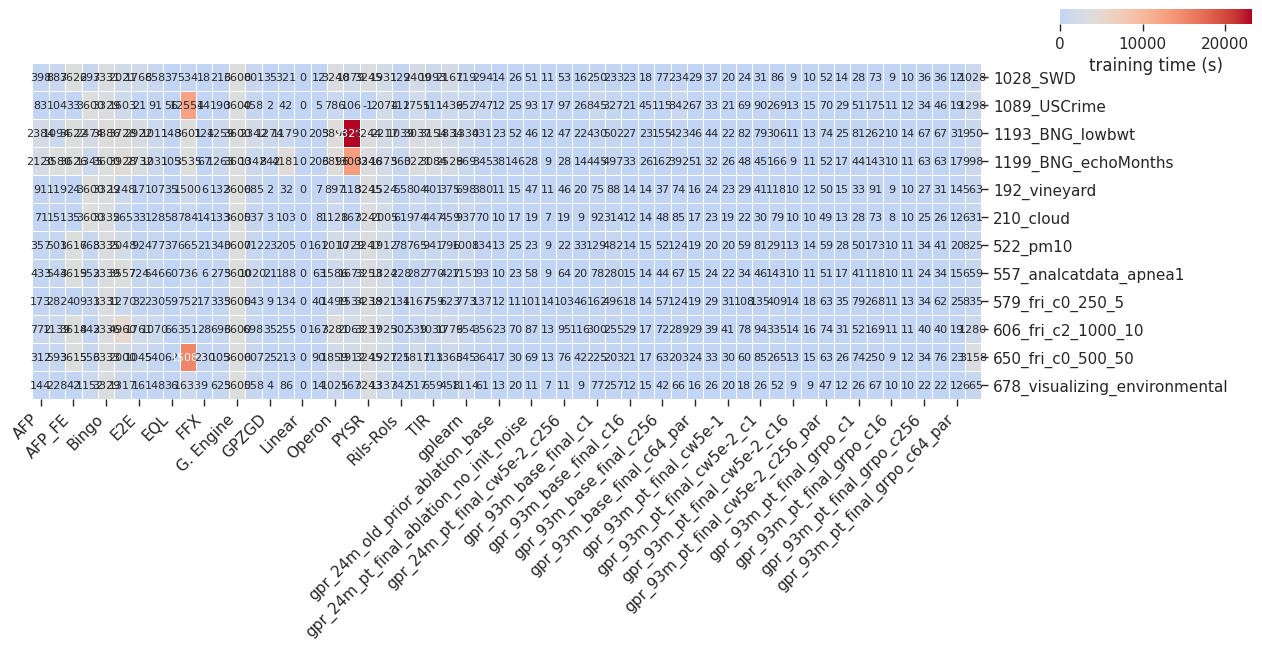

In [15]:
# Size of the best expressions
df_plot_heatmap = df_plot.copy().dropna(subset=['training time (s)'])

# Selecting as final result the best performing r2
idx = df_plot_heatmap.groupby(['algorithm', 'dataset'])['training time (s)'].transform(np.nanmax) == df_plot_heatmap['training time (s)']

# Eliminating duplicated r2 performances by picking the smaller model
df_plot_heatmap = df_plot_heatmap[idx].sort_values(['algorithm', 'dataset', 'training time (s)']).groupby(['algorithm', 'dataset']).head(1)[['algorithm', 'dataset', 'training time (s)']]

df_plot_heatmap = df_plot_heatmap.pivot(columns='algorithm', index='dataset', values='training time (s)').fillna(-1)

g = sns.clustermap(
    df_plot_heatmap,
    annot=True,
    fmt='.0f',
    cmap='coolwarm',
    annot_kws={'size': 8},
    linewidths=0.5,
    square=False,
    center=3600,
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(.86, .92, .128, .019),
    # cbar_pos=(.82, .92, .148, .019),
    cbar_kws={'label': 'training time (s)', "orientation": "horizontal"},
    figsize=(15, 8)
)

g.ax_heatmap.set_ylabel("")
g.ax_heatmap.set_xlabel("")
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)

plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
save(name='training_time', figdir=figdir, tight_layout=False)